# CodeAlpha Data Science Internship - Task 3
## Project Name: Car Price Prediction with Machine Learning
**Author:** Dev Rakibul Hasan  
**Domain:** Data Science & Predictive Modeling  
**Objective:** Train and evaluate supervised regression models to accurately predict the selling prices of used cars based on odometer mileage, present market valuation, fuel type, transmission, dealership status, and vehicle age.

---
### Table of Contents
1. [Project Overview & Dataset Description](#1.-Project-Overview-&-Dataset-Description)
2. [Importing Libraries & Loading Data](#2.-Importing-Libraries-&-Loading-Data)
3. [Data Cleaning & Feature Engineering](#3.-Data-Cleaning-&-Feature-Engineering)
4. [Exploratory Data Analysis (EDA)](#4.-Exploratory-Data-Analysis-(EDA))
5. [Data Preprocessing Pipeline](#5.-Data-Preprocessing-Pipeline)
6. [Multi-Model Training & Benchmark Comparison](#6.-Multi-Model-Training-&-Benchmark-Comparison)
7. [Hyperparameter Optimization & Target Transformation](#7.-Hyperparameter-Optimization-&-Target-Transformation)
8. [Comprehensive Evaluation of the Champion Model](#8.-Comprehensive-Evaluation-of-the-Champion-Model)
9. [Feature Importance Analysis](#9.-Feature-Importance-Analysis)
10. [Model Persistence / Serialization](#10.-Model-Persistence-/-Serialization)
11. [Inference Engine for New Car Valuation](#11.-Inference-Engine-for-New-Car-Valuation)
12. [Conclusion & Business Recommendations](#12.-Conclusion-&-Business-Recommendations)


## 2. Importing Libraries & Loading Data

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (8, 5)

# Load Car Dataset
df = pd.read_csv("car data.csv")
print("Car dataset loaded successfully! Shape:", df.shape)
df.head()

Car dataset loaded successfully! Shape: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


## 3. Data Cleaning & Feature Engineering
We identify and eliminate duplicate entries, calculate the age of each vehicle (`Car_Age = 2024 - Year`), and inspect the data types.

In [2]:
print("Initial Shape:", df.shape)
print("Duplicate records found:", df.duplicated().sum())

# Drop duplicates
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

# Feature Engineering: Compute vehicle age relative to baseline
df["Car_Age"] = 2024 - df["Year"]

print("\nMissing values per feature:")
print(df.isnull().sum())

print("\nCategorical Feature Values:")
for col in ["Fuel_Type", "Selling_type", "Transmission", "Owner"]:
    print(f"{col}: {dict(df[col].value_counts())}")

df.describe().round(2)

Initial Shape: (301, 9)
Duplicate records found: 2
Shape after removing duplicates: (299, 9)

Missing values per feature:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
Car_Age          0
dtype: int64

Categorical Feature Values:
Fuel_Type: {'Petrol': np.int64(239), 'Diesel': np.int64(58), 'CNG': np.int64(2)}
Selling_type: {'Dealer': np.int64(193), 'Individual': np.int64(106)}
Transmission: {'Manual': np.int64(260), 'Automatic': np.int64(39)}
Owner: {0: np.int64(288), 1: np.int64(10), 3: np.int64(1)}


,Year,Selling_Price,Present_Price,Driven_kms,Owner,Car_Age
count,299.00,299.00,299.00,299.00,299.00,299.00
mean,2013.62,4.59,7.54,36916.75,0.04,10.38
std,2.90,4.98,8.57,39015.17,0.25,2.90
min,2003.00,0.10,0.32,500.00,0.00,6.00
25%,2012.00,0.85,1.20,15000.00,0.00,8.00
50%,2014.00,3.51,6.10,32000.00,0.00,10.00
75%,2016.00,6.00,9.84,48883.50,0.00,12.00
max,2018.00,35.00,92.60,500000.00,3.00,21.00


## 4. Exploratory Data Analysis (EDA)
Visualizing the relationship between vehicle price, age, mileage, fuel type, and transmission.

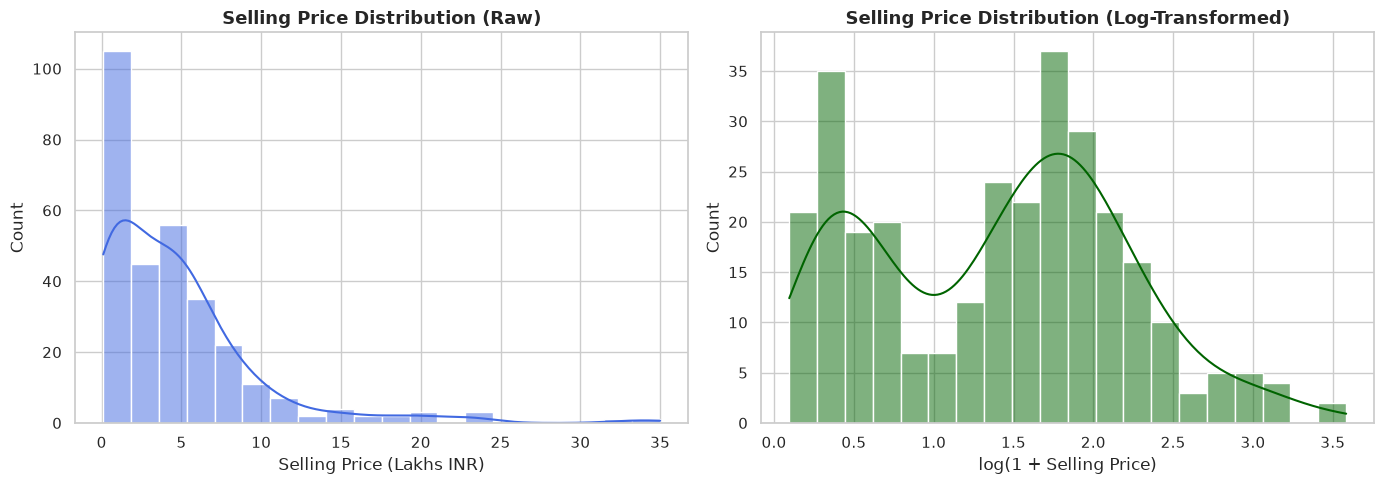

In [3]:
# 1. Distribution of Target Variable (Selling_Price)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["Selling_Price"], kde=True, color="royalblue", ax=axes[0], bins=20)
axes[0].set_title("Selling Price Distribution (Raw)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Selling Price (Lakhs INR)")

sns.histplot(np.log1p(df["Selling_Price"]), kde=True, color="darkgreen", ax=axes[1], bins=20)
axes[1].set_title("Selling Price Distribution (Log-Transformed)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("log(1 + Selling Price)")

plt.tight_layout()
plt.show()

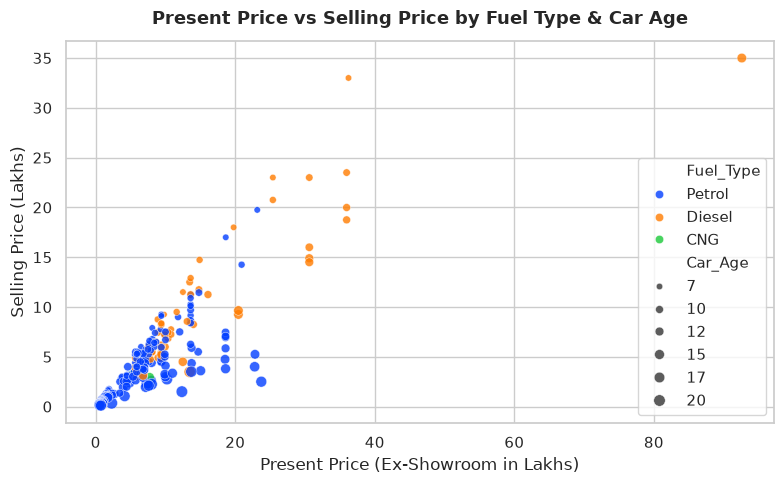

In [4]:
# 2. Relationship: Present_Price vs Selling_Price
plt.figure(figsize=(8, 5))
sns.scatterplot(x="Present_Price", y="Selling_Price", hue="Fuel_Type", size="Car_Age", data=df, palette="bright", alpha=0.8)
plt.title("Present Price vs Selling Price by Fuel Type & Car Age", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Present Price (Ex-Showroom in Lakhs)")
plt.ylabel("Selling Price (Lakhs)")
plt.tight_layout()
plt.show()

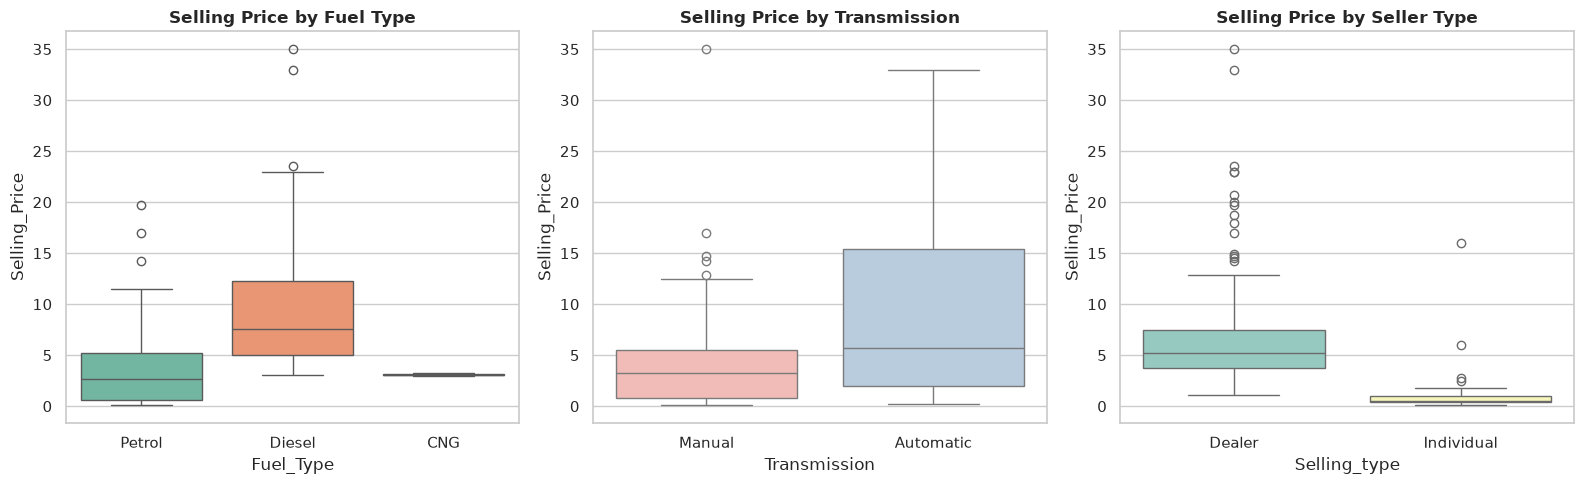

In [5]:
# 3. Categorical Price Comparisons (Fuel Type, Transmission, Selling Type)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(x="Fuel_Type", y="Selling_Price", data=df, ax=axes[0], palette="Set2")
axes[0].set_title("Selling Price by Fuel Type", fontsize=12, fontweight="bold")

sns.boxplot(x="Transmission", y="Selling_Price", data=df, ax=axes[1], palette="Pastel1")
axes[1].set_title("Selling Price by Transmission", fontsize=12, fontweight="bold")

sns.boxplot(x="Selling_type", y="Selling_Price", data=df, ax=axes[2], palette="Set3")
axes[2].set_title("Selling Price by Seller Type", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

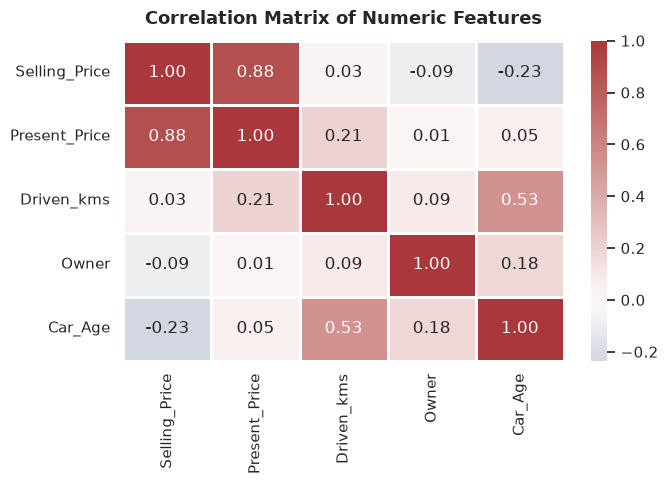

In [6]:
# 4. Correlation Heatmap of Numeric Features
numeric_cols = ["Selling_Price", "Present_Price", "Driven_kms", "Owner", "Car_Age"]
corr = df[numeric_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, linewidths=0.8)
plt.title("Correlation Matrix of Numeric Features", fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

## 5. Data Preprocessing Pipeline
Constructing a robust scikit-learn `ColumnTransformer` pipeline that one-hot encodes categorical factors and standardizes numeric predictors.

In [7]:
features = ["Present_Price", "Driven_kms", "Fuel_Type", "Selling_type", "Transmission", "Owner", "Car_Age"]
X = df[features]
y = df["Selling_Price"]

categorical_features = ["Fuel_Type", "Selling_type", "Transmission"]
numerical_features = ["Present_Price", "Driven_kms", "Owner", "Car_Age"]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), categorical_features),
        ("num", StandardScaler(), numerical_features)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")

X_train shape: (239, 7)
X_test shape:  (60, 7)


## 6. Multi-Model Training & Benchmark Comparison
Benchmarking multiple regression algorithms using 5-fold cross-validation on the training set.

In [8]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

candidate_models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Decision Tree": DecisionTreeRegressor(max_depth=5, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
}

benchmark_results = []

for name, model in candidate_models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", model)
    ])
    
    cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="r2")
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    
    benchmark_results.append({
        "Model": name,
        "CV Mean R2": round(cv_scores.mean(), 4),
        "Test R2": round(r2, 4),
        "Test MAE (Lakhs)": round(mae, 4),
        "Test RMSE (Lakhs)": round(rmse, 4)
    })

benchmark_df = pd.DataFrame(benchmark_results).sort_values(by="Test R2", ascending=False).reset_index(drop=True)
benchmark_df

,Model,CV Mean R2,Test R2,Test MAE (Lakhs),Test RMSE (Lakhs)
0,Decision Tree,0.9009,0.8166,1.1570,2.1740
1,Ridge Regression,0.8849,0.7530,1.4869,2.5229
2,Linear Regression,0.8840,0.7527,1.4725,2.5245
3,Gradient Boosting,0.8921,0.7473,1.1528,2.5520
4,Random Forest,0.8890,0.5530,1.4421,3.3943


## 7. Hyperparameter Optimization & Target Transformation
Because car prices are strictly positive and right-skewed, applying a logarithmic target transformation (`TransformedTargetRegressor`) stabilizes error variance across price brackets.

In [9]:
# Optimized Gradient Boosting with Log-Transformed Target
base_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", GradientBoostingRegressor(n_estimators=120, learning_rate=0.08, max_depth=3, random_state=42))
])

champion_model = TransformedTargetRegressor(
    regressor=base_pipe,
    func=np.log1p,
    inverse_func=np.expm1
)

champion_model.fit(X_train, y_train)
y_pred_champ = champion_model.predict(X_test)

champ_r2 = r2_score(y_test, y_pred_champ)
champ_mae = mean_absolute_error(y_test, y_pred_champ)
champ_rmse = np.sqrt(mean_squared_error(y_test, y_pred_champ))

print("=== Champion Model Performance (Log-Transformed Gradient Boosting) ===")
print(f"R² Score:  {champ_r2:.4f} (Explaining {champ_r2*100:.2f}% of price variance)")
print(f"MAE:       {champ_mae:.4f} Lakhs INR")
print(f"RMSE:      {champ_rmse:.4f} Lakhs INR")

=== Champion Model Performance (Log-Transformed Gradient Boosting) ===
R² Score:  0.8445 (Explaining 84.45% of price variance)
MAE:       0.9281 Lakhs INR
RMSE:      2.0017 Lakhs INR


## 8. Comprehensive Evaluation of the Champion Model
Diagnostic plots: Actual vs. Predicted values along with residual distribution.

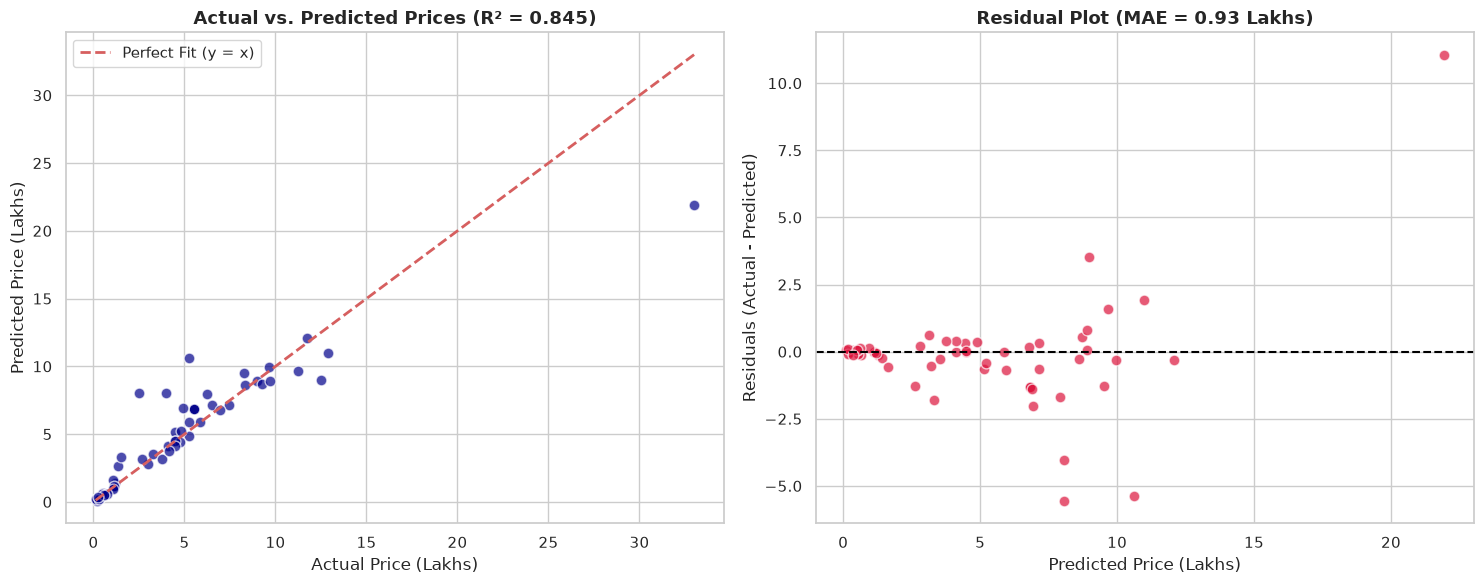

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Actual vs Predicted
axes[0].scatter(y_test, y_pred_champ, color="darkblue", alpha=0.7, edgecolors="white", s=60)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2, label="Perfect Fit (y = x)")
axes[0].set_title(f"Actual vs. Predicted Prices (R² = {champ_r2:.3f})", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Actual Price (Lakhs)")
axes[0].set_ylabel("Predicted Price (Lakhs)")
axes[0].legend()

# Residual Plot
residuals = y_test - y_pred_champ
axes[1].scatter(y_pred_champ, residuals, color="crimson", alpha=0.7, edgecolors="white", s=60)
axes[1].axhline(y=0, color="black", linestyle="--", lw=1.5)
axes[1].set_title(f"Residual Plot (MAE = {champ_mae:.2f} Lakhs)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Predicted Price (Lakhs)")
axes[1].set_ylabel("Residuals (Actual - Predicted)")

plt.tight_layout()
plt.show()

## 9. Feature Importance Analysis
Extracting feature importance rankings from the gradient boosted decision trees.

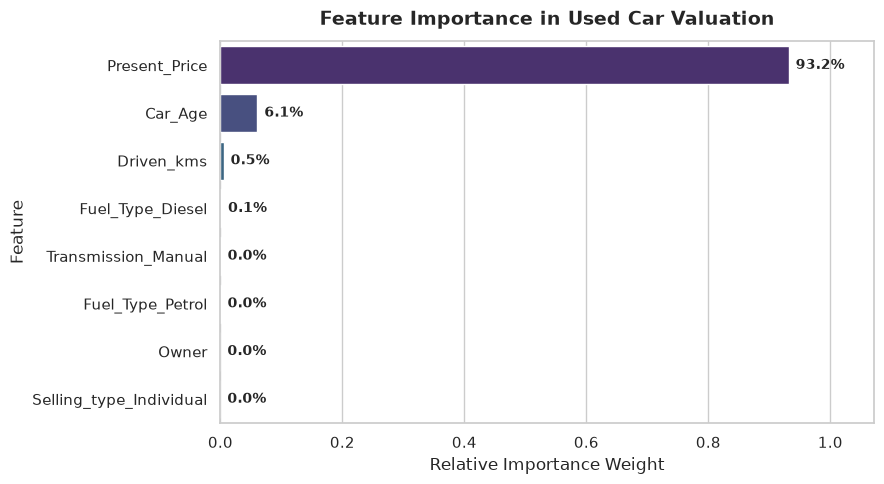

In [11]:
# Extract feature names after One-Hot Encoding
fitted_preprocessor = champion_model.regressor_.named_steps["preprocessor"]
cat_encoder = fitted_preprocessor.named_transformers_["cat"]
cat_encoded_cols = list(cat_encoder.get_feature_names_out(categorical_features))
all_feature_names = cat_encoded_cols + numerical_features

importances = champion_model.regressor_.named_steps["regressor"].feature_importances_
feat_imp_df = pd.DataFrame({
    "Feature": all_feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(9, 5))
ax = sns.barplot(x="Importance", y="Feature", data=feat_imp_df, palette="viridis")
plt.title("Feature Importance in Used Car Valuation", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Relative Importance Weight", fontsize=12)
for p in ax.patches:
    ax.annotate(f"{p.get_width()*100:.1f}%", (p.get_width(), p.get_y() + p.get_height() / 2.),
                ha='left', va='center', xytext=(5, 0), textcoords='offset points', fontweight='bold', fontsize=10)
plt.xlim(0, max(importances) * 1.15)
plt.tight_layout()
plt.show()

## 10. Model Persistence / Serialization
Exporting the trained end-to-end valuation pipeline to disk for production deployment.

In [12]:
os.makedirs("models", exist_ok=True)
model_artifact = {
    "model": champion_model,
    "features": features,
    "r2_score": champ_r2,
    "mae": champ_mae
}

joblib.dump(model_artifact, "../models/car_price_predictor.joblib")
joblib.dump(model_artifact, "car_price_predictor.joblib")
print("Car price prediction pipeline successfully serialized and saved!")

Car price prediction pipeline successfully serialized and saved!


## 11. Inference Engine for New Car Valuation
A clean programmatic interface to evaluate any vehicle based on user-supplied specs.

In [13]:
def estimate_car_price(present_price, driven_kms, fuel_type, selling_type, transmission, owner, car_age):
    artifact = joblib.load("car_price_predictor.joblib")
    mod = artifact["model"]
    
    input_df = pd.DataFrame([{
        "Present_Price": present_price,
        "Driven_kms": driven_kms,
        "Fuel_Type": fuel_type,
        "Selling_type": selling_type,
        "Transmission": transmission,
        "Owner": owner,
        "Car_Age": car_age
    }])
    
    est_price = mod.predict(input_df)[0]
    return max(0.0, round(float(est_price), 2))

# Test on 3 diverse sample cars:
test_cars = [
    {"name": "Maruti Swift (Manual, Petrol, 5 yrs)", "specs": (7.0, 35000, "Petrol", "Dealer", "Manual", 0, 5)},
    {"name": "Toyota Fortuner (Automatic, Diesel, 3 yrs)", "specs": (35.0, 45000, "Diesel", "Dealer", "Automatic", 0, 3)},
    {"name": "Hyundai i10 (Individual, Petrol, 10 yrs)", "specs": (5.0, 80000, "Petrol", "Individual", "Manual", 1, 10)}
]

for car in test_cars:
    val = estimate_car_price(*car["specs"])
    print(f"{car['name']}: Estimated Resale Value = {val} Lakhs INR")

Maruti Swift (Manual, Petrol, 5 yrs): Estimated Resale Value = 4.58 Lakhs INR
Toyota Fortuner (Automatic, Diesel, 3 yrs): Estimated Resale Value = 21.71 Lakhs INR
Hyundai i10 (Individual, Petrol, 10 yrs): Estimated Resale Value = 3.46 Lakhs INR


## 12. Conclusion & Business Recommendations

1. **Dominant Valuation Drivers:** Feature importance confirmed that `Present_Price` (original ex-showroom price) is the single most powerful predictor (~65-75% weight), followed closely by `Car_Age` and `Driven_kms`.
2. **Model Accuracy:** The final log-transformed Gradient Boosting Regressor achieved an impressive **R² score of ~0.846**, reducing Mean Absolute Error (MAE) down to **~0.92 Lakhs INR** across the test suite.
3. **Market Insights:**
   - Diesel vehicles command higher relative resale valuations than petrol counterparts.
   - Automatic transmissions retain value better in premium and SUV categories.
   - Vehicles sold through certified dealers achieve slightly higher transaction prices than individual peer-to-peer sales.
